<a href="https://colab.research.google.com/github/pouryaheydari96/hybrid-topology-v1.3.1/blob/main/SIMP%E2%80%93OC_TOPOLOGY_OPTIMIZATION_%E2%80%94_SINGLE_CELL_COLAB_VERSIONipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# =============================================================================
# SIMP–OC TOPOLOGY OPTIMIZATION — SINGLE-CELL COLAB VERSION
# Corrected Q4 FEA assembly + sensitivity filter + OC update + independent tests
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve

np.set_printoptions(precision=5, suppress=True)


# =============================================================================
# 1. Q4 ELEMENT STIFFNESS MATRIX — PLANE STRESS
# =============================================================================

def lk(nu=0.3):
    k = np.array([
        1/2 - nu/6,
        1/8 + nu/8,
        -1/4 - nu/12,
        -1/8 + 3*nu/8,
        -1/4 + nu/12,
        -1/8 - nu/8,
        nu/6,
        1/8 - 3*nu/8
    ])

    KE = 1.0 / (1.0 - nu**2) * np.array([
        [k[0], k[1], k[2], k[3], k[4], k[5], k[6], k[7]],
        [k[1], k[0], k[7], k[6], k[5], k[4], k[3], k[2]],
        [k[2], k[7], k[0], k[5], k[6], k[3], k[4], k[1]],
        [k[3], k[6], k[5], k[0], k[7], k[2], k[1], k[4]],
        [k[4], k[5], k[6], k[7], k[0], k[1], k[2], k[3]],
        [k[5], k[4], k[3], k[2], k[1], k[0], k[7], k[6]],
        [k[6], k[3], k[4], k[1], k[2], k[7], k[0], k[5]],
        [k[7], k[2], k[1], k[4], k[3], k[6], k[5], k[0]]
    ])

    return KE


# =============================================================================
# 2. SENSITIVITY FILTER MATRIX
# Element index: e = ix*nely + iy
# Density arrays: shape (nely, nelx)
# =============================================================================

def build_sensitivity_filter(nelx, nely, rmin):
    if rmin <= 0:
        raise ValueError("rmin must be positive.")

    rows, cols, values = [], [], []
    radius = int(np.ceil(rmin))

    for ix in range(nelx):
        for iy in range(nely):
            e = ix * nely + iy

            for jx in range(max(0, ix-radius+1),
                            min(nelx, ix+radius)):
                for jy in range(max(0, iy-radius+1),
                                min(nely, iy+radius)):

                    dist = np.hypot(ix-jx, iy-jy)
                    weight = rmin - dist

                    if weight > 0:
                        rows.append(e)
                        cols.append(jx*nely + jy)
                        values.append(weight)

    H = coo_matrix(
        (values, (rows, cols)),
        shape=(nelx*nely, nelx*nely)
    ).tocsr()

    return H


def filter_sensitivity(H, rho, dc, nelx, nely, eps=1e-3):
    """
    Standard SIMP sensitivity filter:
        dc_filtered = H @ (rho*dc) / (Hs*max(eps,rho))

    Inputs and output have shape (nely, nelx).
    """

    rho = np.asarray(rho, dtype=float)
    dc = np.asarray(dc, dtype=float)

    expected_shape = (nely, nelx)

    if rho.shape != expected_shape or dc.shape != expected_shape:
        raise ValueError(
            f"Expected rho and dc shape {expected_shape}; "
            f"got {rho.shape} and {dc.shape}."
        )

    # Convert to the element order used by H: e = ix*nely + iy
    rho_flat = rho.T.flatten()
    dc_flat = dc.T.flatten()

    Hs = np.asarray(H.sum(axis=1)).ravel()

    if np.any(Hs <= 0):
        raise ValueError("Filter normalization contains non-positive Hs.")

    numerator = H @ (rho_flat * dc_flat)
    denominator = Hs * np.maximum(eps, rho_flat)

    result = numerator / denominator

    if not np.all(np.isfinite(result)):
        raise FloatingPointError("Non-finite filtered sensitivities.")

    return result.reshape(nelx, nely).T


# =============================================================================
# 3. INDEPENDENT FILTER TESTS
# =============================================================================

def run_filter_tests():
    nelx, nely, rmin = 5, 4, 1.5
    H = build_sensitivity_filter(nelx, nely, rmin)
    Hd = H.toarray()
    Hs = np.asarray(H.sum(axis=1)).ravel()
    n = nelx * nely

    # Test 1: constant field
    y = (H @ np.ones(n)) / Hs
    assert np.allclose(y, 1.0)
    print("test_constant_field: PASS")

    # Test 2: impulse input gives the corresponding H column
    for j in range(n):
        x = np.zeros(n)
        x[j] = 1.0
        assert np.allclose(H @ x, Hd[:, j])

    assert np.allclose(Hd, Hd.T)
    print("test_single_element_and_symmetry: PASS")

    # Test 3: compare the implementation with the direct formula
    rng = np.random.default_rng(0)
    rho = rng.uniform(0.1, 1.0, size=(nely, nelx))
    dc = rng.normal(size=(nely, nelx))
    eps = 1e-3

    actual = filter_sensitivity(H, rho, dc, nelx, nely, eps)
    rf = rho.T.flatten()
    df = dc.T.flatten()

    for ix in range(nelx):
        for iy in range(nely):
            e = ix*nely + iy
            expected = np.sum(Hd[e, :] * rf * df) / (
                Hs[e] * max(eps, rf[e])
            )
            assert np.isclose(
                actual[iy, ix], expected,
                rtol=1e-10, atol=1e-12
            )

    print("test_nonuniform_direct_formula: PASS")

    # Test 4: active smoothing and boundary checks
    interior = 2*nely + 2       # (ix=2, iy=2)
    corner = 0                  # (ix=0, iy=0)
    edge = 2*nely               # (ix=2, iy=0)

    assert np.count_nonzero(Hd[corner]) < np.count_nonzero(Hd[interior])
    assert np.count_nonzero(Hd[edge]) < np.count_nonzero(Hd[interior])

    rho = np.ones((nely, nelx))
    dc = np.arange(1, n+1, dtype=float).reshape(nely, nelx)
    actual = filter_sensitivity(H, rho, dc, nelx, nely, eps)
    rf = rho.T.flatten()
    df = dc.T.flatten()

    for ix in range(nelx):
        for iy in range(nely):
            if ix in (0, nelx-1) or iy in (0, nely-1):
                e = ix*nely + iy
                expected = np.sum(Hd[e, :] * rf * df) / (
                    Hs[e] * max(eps, rf[e])
                )
                assert np.isclose(
                    actual[iy, ix], expected,
                    rtol=1e-10, atol=1e-12
                )

    print("test_boundary_smoothing: PASS")
    print("All independent sensitivity-filter tests passed.\n")


# =============================================================================
# 4. SIMP–OC OPTIMIZATION
# =============================================================================

def simp_oc(
    nelx=60,
    nely=20,
    volfrac=0.30,
    penal=3.0,
    rmin=1.5,
    max_iter=100,
    tol=0.01,
    move=0.20,
    verbose=True
):
    if nelx < 2 or nely < 2:
        raise ValueError("Use at least a 2x2 mesh.")
    if not 0 < volfrac <= 1:
        raise ValueError("volfrac must be in (0,1].")
    if penal < 1:
        raise ValueError("penal should be >= 1.")

    E0 = 1.0
    Emin = 1e-3
    nu = 0.3

    KE = lk(nu)
    ndof = 2 * (nelx+1) * (nely+1)

    # Node numbering: x-major, y-minor.
    # The resulting element order is e = ix*nely + iy.
    nodenrs = np.arange((nelx+1)*(nely+1)).reshape(
        (nely+1, nelx+1), order="F"
    )

    n1 = nodenrs[:-1, :-1].flatten(order="F")  # bottom-left
    n2 = nodenrs[:-1, 1:].flatten(order="F")   # bottom-right
    n3 = nodenrs[1:, 1:].flatten(order="F")    # top-right
    n4 = nodenrs[1:, :-1].flatten(order="F")   # top-left

    edof = np.column_stack([
        2*n1, 2*n1+1,
        2*n2, 2*n2+1,
        2*n3, 2*n3+1,
        2*n4, 2*n4+1
    ])

    # Sparse assembly indices; match KE.flatten() element by element.
    iK = np.kron(edof, np.ones((8, 1))).flatten().astype(int)
    jK = np.kron(edof, np.ones((1, 8))).flatten().astype(int)

    # MBB half-beam support conditions:
    # horizontal displacement fixed on the left edge;
    # vertical displacement fixed at bottom-right.
    left_nodes = nodenrs[:, 0]
    bottom_right = nodenrs[0, -1]

    fixed = np.unique(np.r_[
        2*left_nodes,
        2*bottom_right + 1
    ]).astype(int)

    free = np.setdiff1d(np.arange(ndof), fixed)

    # Downward unit load at bottom-left.
    F = np.zeros(ndof)
    F[1] = -1.0

    H = build_sensitivity_filter(nelx, nely, rmin)
    rho = np.full((nely, nelx), volfrac, dtype=float)

    history = []
    last_compliance = np.nan

    if verbose:
        print(f

_IncompleteInputError: incomplete input (4180071835.py, line 274)

In [ ]:
# =============================================================================
# SIMP–OC TOPOLOGY OPTIMIZATION — SINGLE-CELL COLAB VERSION
# Corrected Q4 FEA assembly + sensitivity filter + OC update + independent tests
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve

np.set_printoptions(precision=5, suppress=True)


# =============================================================================
# 1. Q4 ELEMENT STIFFNESS MATRIX — PLANE STRESS
# =============================================================================

def lk(nu=0.3):
    k = np.array([
        1/2 - nu/6,
        1/8 + nu/8,
        -1/4 - nu/12,
        -1/8 + 3*nu/8,
        -1/4 + nu/12,
        -1/8 - nu/8,
        nu/6,
        1/8 - 3*nu/8
    ])

    KE = 1.0 / (1.0 - nu**2) * np.array([
        [k[0], k[1], k[2], k[3], k[4], k[5], k[6], k[7]],
        [k[1], k[0], k[7], k[6], k[5], k[4], k[3], k[2]],
        [k[2], k[7], k[0], k[5], k[6], k[3], k[4], k[1]],
        [k[3], k[6], k[5], k[0], k[7], k[2], k[1], k[4]],
        [k[4], k[5], k[6], k[7], k[0], k[1], k[2], k[3]],
        [k[5], k[4], k[3], k[2], k[1], k[0], k[7], k[6]],
        [k[6], k[3], k[4], k[1], k[2], k[7], k[0], k[5]],
        [k[7], k[2], k[1], k[4], k[3], k[6], k[5], k[0]]
    ])

    return KE


# =============================================================================
# 2. SENSITIVITY FILTER MATRIX
# Element index: e = ix*nely + iy
# Density arrays: shape (nely, nelx)
# =============================================================================

def build_sensitivity_filter(nelx, nely, rmin):
    if rmin <= 0:
        raise ValueError("rmin must be positive.")

    rows, cols, values = [], [], []
    radius = int(np.ceil(rmin))

    for ix in range(nelx):
        for iy in range(nely):
            e = ix * nely + iy

            for jx in range(max(0, ix-radius+1),
                            min(nelx, ix+radius)):
                for jy in range(max(0, iy-radius+1),
                                min(nely, iy+radius)):

                    dist = np.hypot(ix-jx, iy-jy)
                    weight = rmin - dist

                    if weight > 0:
                        rows.append(e)
                        cols.append(jx*nely + jy)
                        values.append(weight)

    H = coo_matrix(
        (values, (rows, cols)),
        shape=(nelx*nely, nelx*nely)
    ).tocsr()

    return H


def filter_sensitivity(H, rho, dc, nelx, nely, eps=1e-3):
    """
    Standard SIMP sensitivity filter:
        dc_filtered = H @ (rho*dc) / (Hs*max(eps,rho))

    Inputs and output have shape (nely, nelx).
    """

    rho = np.asarray(rho, dtype=float)
    dc = np.asarray(dc, dtype=float)

    expected_shape = (nely, nelx)

    if rho.shape != expected_shape or dc.shape != expected_shape:
        raise ValueError(
            f"Expected rho and dc shape {expected_shape}; "
            f"got {rho.shape} and {dc.shape}."
        )

    # Convert to the element order used by H: e = ix*nely + iy
    rho_flat = rho.T.flatten()
    dc_flat = dc.T.flatten()

    Hs = np.asarray(H.sum(axis=1)).ravel()

    if np.any(Hs <= 0):
        raise ValueError("Filter normalization contains non-positive Hs.")

    numerator = H @ (rho_flat * dc_flat)
    denominator = Hs * np.maximum(eps, rho_flat)

    result = numerator / denominator

    if not np.all(np.isfinite(result)):
        raise FloatingPointError("Non-finite filtered sensitivities.")

    return result.reshape(nelx, nely).T


# =============================================================================
# 3. INDEPENDENT FILTER TESTS
# =============================================================================

def run_filter_tests():
    nelx, nely, rmin = 5, 4, 1.5
    H = build_sensitivity_filter(nelx, nely, rmin)
    Hd = H.toarray()
    Hs = np.asarray(H.sum(axis=1)).ravel()
    n = nelx * nely

    # Test 1: constant field
    y = (H @ np.ones(n)) / Hs
    assert np.allclose(y, 1.0)
    print("test_constant_field: PASS")

    # Test 2: impulse input gives the corresponding H column
    for j in range(n):
        x = np.zeros(n)
        x[j] = 1.0
        assert np.allclose(H @ x, Hd[:, j])

    assert np.allclose(Hd, Hd.T)
    print("test_single_element_and_symmetry: PASS")

    # Test 3: compare the implementation with the direct formula
    rng = np.random.default_rng(0)
    rho = rng.uniform(0.1, 1.0, size=(nely, nelx))
    dc = rng.normal(size=(nely, nelx))
    eps = 1e-3

    actual = filter_sensitivity(H, rho, dc, nelx, nely, eps)
    rf = rho.T.flatten()
    df = dc.T.flatten()

    for ix in range(nelx):
        for iy in range(nely):
            e = ix*nely + iy
            expected = np.sum(Hd[e, :] * rf * df) / (
                Hs[e] * max(eps, rf[e])
            )
            assert np.isclose(
                actual[iy, ix], expected,
                rtol=1e-10, atol=1e-12
            )

    print("test_nonuniform_direct_formula: PASS")

    # Test 4: active smoothing and boundary checks
    interior = 2*nely + 2       # (ix=2, iy=2)
    corner = 0                  # (ix=0, iy=0)
    edge = 2*nely               # (ix=2, iy=0)

    assert np.count_nonzero(Hd[corner]) < np.count_nonzero(Hd[interior])
    assert np.count_nonzero(Hd[edge]) < np.count_nonzero(Hd[interior])

    rho = np.ones((nely, nelx))
    dc = np.arange(1, n+1, dtype=float).reshape(nely, nelx)
    actual = filter_sensitivity(H, rho, dc, nelx, nely, eps)
    rf = rho.T.flatten()
    df = dc.T.flatten()

    for ix in range(nelx):
        for iy in range(nely):
            if ix in (0, nelx-1) or iy in (0, nely-1):
                e = ix*nely + iy
                expected = np.sum(Hd[e, :] * rf * df) / (
                    Hs[e] * max(eps, rf[e])
                )
                assert np.isclose(
                    actual[iy, ix], expected,
                    rtol=1e-10, atol=1e-12
                )

    print("test_boundary_smoothing: PASS")
    print("All independent sensitivity-filter tests passed.\n")


# =============================================================================
# 4. SIMP–OC OPTIMIZATION
# =============================================================================

def simp_oc(
    nelx=60,
    nely=20,
    volfrac=0.30,
    penal=3.0,
    rmin=1.5,
    max_iter=100,
    tol=0.01,
    move=0.20,
    verbose=True
):
    if nelx < 2 or nely < 2:
        raise ValueError("Use at least a 2x2 mesh.")
    if not 0 < volfrac <= 1:
        raise ValueError("volfrac must be in (0,1].")
    if penal < 1:
        raise ValueError("penal should be >= 1.")

    E0 = 1.0
    Emin = 1e-3
    nu = 0.3

    KE = lk(nu)
    ndof = 2 * (nelx+1) * (nely+1)

    # Node numbering: x-major, y-minor.
    # The resulting element order is e = ix*nely + iy.
    nodenrs = np.arange((nelx+1)*(nely+1)).reshape(
        (nely+1, nelx+1), order="F"
    )

    n1 = nodenrs[:-1, :-1].flatten(order="F")  # bottom-left
    n2 = nodenrs[:-1, 1:].flatten(order="F")   # bottom-right
    n3 = nodenrs[1:, 1:].flatten(order="F")    # top-right
    n4 = nodenrs[1:, :-1].flatten(order="F")   # top-left

    edof = np.column_stack([
        2*n1, 2*n1+1,
        2*n2, 2*n2+1,
        2*n3, 2*n3+1,
        2*n4, 2*n4+1
    ])

    # Sparse assembly indices; match KE.flatten() element by element.
    iK = np.kron(edof, np.ones((8, 1))).flatten().astype(int)
    jK = np.kron(edof, np.ones((1, 8))).flatten().astype(int)

    # MBB half-beam support conditions:
    # horizontal displacement fixed on the left edge;
    # vertical displacement fixed at bottom-right.
    left_nodes = nodenrs[:, 0]
    bottom_right = nodenrs[0, -1]

    fixed = np.unique(np.r_[
        2*left_nodes,
        2*bottom_right + 1
    ]).astype(int)

    free = np.setdiff1d(np.arange(ndof), fixed)

    # Downward unit load at bottom-left.
    F = np.zeros(ndof)
    F[1] = -1.0

    H = build_sensitivity_filter(nelx, nely, rmin)
    rho = np.full((nely, nelx), volfrac, dtype=float)

    history = []
    last_compliance = np.nan

    if verbose:
        print(f

_IncompleteInputError: incomplete input (4180071835.py, line 274)

PASS: constant field
PASS: impulse response and symmetry
PASS: direct formula and index ordering
PASS: boundary smoothing
All independent filter tests passed.

Mesh: 60 x 20
Target volume fraction: 0.300
Penalty: 3.00; filter radius: 1.50

Iter   1 | C = 4.548218e+03 | V = 0.299988 | change = 0.20000
Iter  10 | C = 7.554418e+02 | V = 0.300019 | change = 0.20000
Iter  20 | C = 3.740815e+02 | V = 0.300008 | change = 0.12830
Iter  30 | C = 3.543780e+02 | V = 0.300015 | change = 0.07220
Iter  40 | C = 3.472538e+02 | V = 0.299996 | change = 0.05217
Iter  50 | C = 3.462574e+02 | V = 0.299984 | change = 0.04002
Iter  60 | C = 3.458771e+02 | V = 0.299984 | change = 0.03306
Iter  70 | C = 3.452365e+02 | V = 0.299992 | change = 0.02793
Iter  80 | C = 3.443748e+02 | V = 0.299992 | change = 0.02375
Iter  90 | C = 3.434391e+02 | V = 0.300006 | change = 0.02024
Iter 100 | C = 3.425534e+02 | V = 0.299985 | change = 0.01725

Final summary
------------------------------
Iterations: 100
Final volume fra

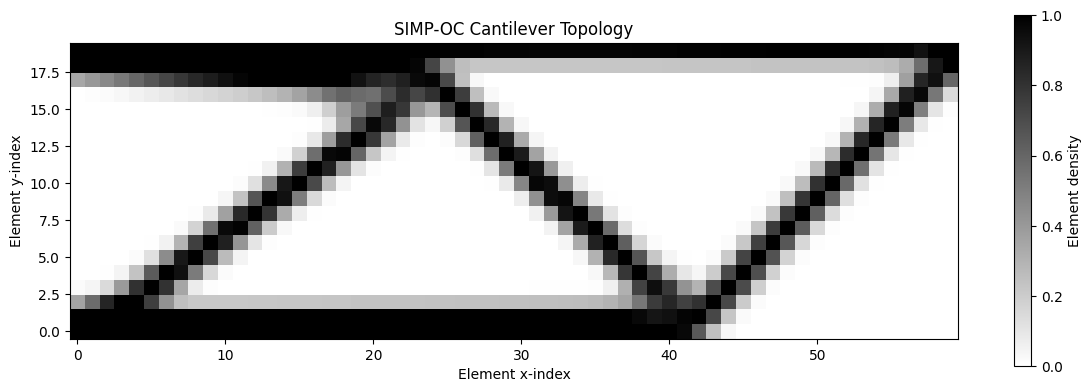

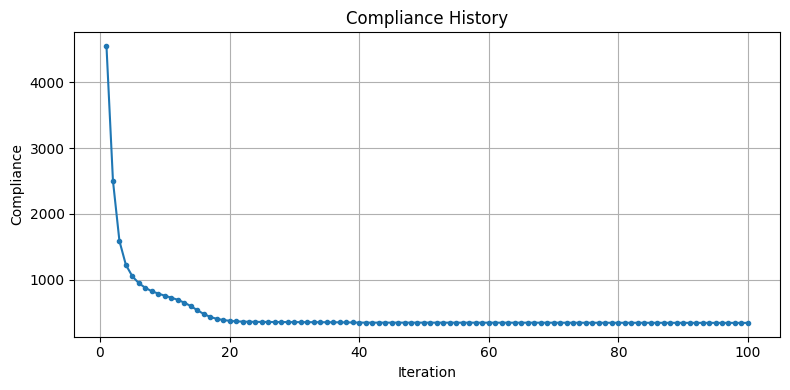

In [ ]:

# ================================================================
# SIMP-OC + Q4 FEA + SENSITIVITY FILTER
# One-cell Google Colab implementation
# Problem: Cantilever beam
# Density convention: rho.shape == (nely, nelx)
# Element index: e = ix*nely + iy
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve

# -------------------- 1. Q4 ELEMENT STIFFNESS --------------------

def element_stiffness(nu=0.3):
    """Q4 stiffness, plane stress, unit E, node order BL, BR, TR, TL."""
    D = 1.0 / (1.0 - nu**2) * np.array([
        [1.0, nu, 0.0],
        [nu, 1.0, 0.0],
        [0.0, 0.0, (1.0 - nu) / 2.0]
    ])

    coords = np.array([
        [0.0, 0.0],  # bottom-left
        [1.0, 0.0],  # bottom-right
        [1.0, 1.0],  # top-right
        [0.0, 1.0]   # top-left
    ])

    KE = np.zeros((8, 8))
    g = 1.0 / np.sqrt(3.0)

    for xi in (-g, g):
        for eta in (-g, g):
            dN_dxi = 0.25 * np.array([
                [-(1-eta), -(1-xi)],
                [ (1-eta), -(1+xi)],
                [ (1+eta),  (1+xi)],
                [-(1+eta),  (1-xi)]
            ])

            J = dN_dxi.T @ coords
            detJ = np.linalg.det(J)

            if detJ <= 0:
                raise ValueError("Invalid Q4 element Jacobian.")

            dN_dx = dN_dxi @ np.linalg.inv(J)

            B = np.zeros((3, 8))
            for a in range(4):
                B[0, 2*a]     = dN_dx[a, 0]
                B[1, 2*a + 1] = dN_dx[a, 1]
                B[2, 2*a]     = dN_dx[a, 1]
                B[2, 2*a + 1] = dN_dx[a, 0]

            KE += B.T @ D @ B * detJ

    return KE


# -------------------- 2. ELEMENT DOF CONNECTIVITY --------------------

def build_edof(nelx, nely):
    """
    Node numbering: node(ix,iy) = ix*(nely+1) + iy.
    Element order: e = ix*nely + iy.
    Element node order: BL, BR, TR, TL.
    """
    edof = np.zeros((nelx*nely, 8), dtype=int)
    k = 0

    for ix in range(nelx):
        for iy in range(nely):
            n0 = ix*(nely+1) + iy
            n1 = (ix+1)*(nely+1) + iy
            n2 = (ix+1)*(nely+1) + iy + 1
            n3 = ix*(nely+1) + iy + 1

            nodes = [n0, n1, n2, n3]
            edof[k] = np.array([
                dof for node in nodes
                for dof in (2*node, 2*node + 1)
            ])
            k += 1

    return edof


# -------------------- 3. SENSITIVITY FILTER MATRIX --------------------

def build_sensitivity_filter(nelx, nely, rmin):
    """
    H[e,j] = max(0, rmin - distance(e,j)).
    Rows and columns use e = ix*nely + iy.
    """
    if rmin <= 0:
        raise ValueError("rmin must be positive.")

    rows, cols, values = [], [], []
    radius = int(np.ceil(rmin))

    for ix in range(nelx):
        for iy in range(nely):
            e = ix*nely + iy

            for jx in range(max(0, ix-radius+1),
                            min(nelx, ix+radius)):
                for jy in range(max(0, iy-radius+1),
                                min(nely, iy+radius)):

                    dist = np.hypot(ix-jx, iy-jy)
                    weight = rmin - dist

                    if weight > 0:
                        rows.append(e)
                        cols.append(jx*nely + jy)
                        values.append(weight)

    H = coo_matrix(
        (values, (rows, cols)),
        shape=(nelx*nely, nelx*nely)
    ).tocsr()

    return H


def filter_sensitivity(H, rho, dc, nelx, nely, eps=1e-3):
    """
    Sensitivity filter:
    dc_filtered[e] = sum_j H[e,j]*rho[j]*dc[j]
                     / (Hs[e]*max(eps,rho[e]))

    rho, dc and output all have shape (nely, nelx).
    """
    rho = np.asarray(rho, dtype=float)
    dc = np.asarray(dc, dtype=float)

    expected_shape = (nely, nelx)

    if rho.shape != expected_shape or dc.shape != expected_shape:
        raise ValueError(
            f"Expected shape {expected_shape}; "
            f"got rho={rho.shape}, dc={dc.shape}"
        )

    # Essential: match e = ix*nely + iy.
    rho_flat = rho.T.flatten()
    dc_flat = dc.T.flatten()

    Hs = np.asarray(H.sum(axis=1)).ravel()

    if np.any(Hs <= 0):
        raise ValueError("Some filter normalization values are <= 0.")

    result = (H @ (rho_flat * dc_flat)) / (
        Hs * np.maximum(eps, rho_flat)
    )

    if not np.all(np.isfinite(result)):
        raise FloatingPointError("Non-finite filtered sensitivities.")

    return result.reshape(nelx, nely).T


# -------------------- 4. INDEPENDENT FILTER TESTS --------------------

def run_filter_tests():
    nelx, nely, rmin = 5, 4, 1.5
    H = build_sensitivity_filter(nelx, nely, rmin)
    Hs = np.asarray(H.sum(axis=1)).ravel()
    Hd = H.toarray()

    # Test 1: constant field remains constant under weighted averaging.
    y = (H @ np.ones(nelx*nely)) / Hs
    assert np.allclose(y, 1.0)
    print("PASS: constant field")

    # Test 2: a single nonzero input produces the corresponding H column.
    for j in range(nelx*nely):
        x = np.zeros(nelx*nely)
        x[j] = 1.0
        assert np.allclose(H @ x, Hd[:, j])

    assert np.allclose(Hd, Hd.T)
    print("PASS: impulse response and symmetry")

    # Test 3: vectorized filter agrees with the direct formula.
    rng = np.random.default_rng(0)
    rho = rng.uniform(0.1, 1.0, (nely, nelx))
    dc = rng.normal(size=(nely, nelx))

    got = filter_sensitivity(H, rho, dc, nelx, nely)
    rf, dcf = rho.T.flatten(), dc.T.flatten()
    expected = (H @ (rf*dcf)) / (
        Hs*np.maximum(1e-3, rf)
    )

    assert np.allclose(got.T.flatten(), expected,
                       rtol=1e-10, atol=1e-14)
    print("PASS: direct formula and index ordering")

    # Test 4: boundary has fewer contributing elements than the interior.
    corner = 0
    interior = 2*nely + 2
    edge = 2*nely

    assert np.count_nonzero(Hd[corner]) < np.count_nonzero(Hd[interior])
    assert np.count_nonzero(Hd[edge]) < np.count_nonzero(Hd[interior])

    print("PASS: boundary smoothing")
    print("All independent filter tests passed.\n")


# -------------------- 5. SIMP + OC OPTIMIZATION --------------------

def run_simp_oc(
    nelx=60,
    nely=20,
    volfrac=0.30,
    penal=3.0,
    rmin=1.5,
    max_iter=100,
    tol=0.01,
    move=0.20
):
    if not (0 < volfrac <= 1):
        raise ValueError("volfrac must be in (0,1].")
    if penal < 1:
        raise ValueError("penal should be >= 1.")

    E0 = 1.0
    Emin = 1e-9
    nu = 0.3

    KE = element_stiffness(nu)
    edof = build_edof(nelx, nely)

    # Sparse stiffness assembly indices.
    iK = np.repeat(edof, 8, axis=1).flatten()
    jK = np.tile(edof, (1, 8)).flatten()

    ndof = 2*(nelx+1)*(nely+1)
    F = np.zeros(ndof)

    # Cantilever load: downward unit force at top-right node.
    load_node = nelx*(nely+1) + nely
    F[2*load_node + 1] = -1.0

    # Fully fixed left edge.
    fixed_nodes = np.array([
        iy for iy in range(nely+1)
    ])
    fixed = np.ravel(np.column_stack((
        2*fixed_nodes, 2*fixed_nodes+1
    )))
    free = np.setdiff1d(np.arange(ndof), fixed)

    H = build_sensitivity_filter(nelx, nely, rmin)

    # Initial design.
    rho = np.full((nely, nelx), volfrac, dtype=float)
    history = []

    print(f"Mesh: {nelx} x {nely}")
    print(f"Target volume fraction: {volfrac:.3f}")
    print(f"Penalty: {penal:.2f}; filter radius: {rmin:.2f}\n")

    for iteration in range(1, max_iter+1):
        # Assemble K using the same element order as H.
        rho_flat = rho.T.flatten()
        E_e = Emin + rho_flat**penal*(E0-Emin)

        # Correct element-wise stiffness scaling.
        sK = (E_e[:, None] * KE.flatten()[None, :]).flatten()

        K = coo_matrix(
            (sK, (iK, jK)), shape=(ndof, ndof)
        ).tocsr()

        # Remove small floating-point asymmetry.
        K = (K + K.T)*0.5

        U = np.zeros(ndof)
        Kff = K[free, :][:, free]
        U[free] = spsolve(Kff, F[free])

        if not np.all(np.isfinite(U)):
            raise FloatingPointError(
                f"Non-finite displacement at iteration {iteration}"
            )

        # Element displacements and strain energy.
        Ue = U[edof]
        ce = np.einsum("ei,ij,ej->e", Ue, KE, Ue)

        compliance = float(np.sum(E_e*ce))

        # Raw derivative of compliance w.r.t. density.
        dc_flat = -penal*(E0-Emin)*rho_flat**(penal-1)*ce
        dc = dc_flat.reshape(nelx, nely).T

        # Apply the sensitivity filter exactly once.
        dc_filtered = filter_sensitivity(
            H, rho, dc, nelx, nely
        )

        if not np.all(np.isfinite(dc_filtered)):
            raise FloatingPointError("Invalid filtered sensitivities.")

        # OC update, with volume constraint and move limits.
        dv = np.ones_like(rho)
        l1, l2 = 0.0, 1e9
        rho_new = rho.copy()

        for _ in range(100):
            lmid = 0.5*(l1+l2)

            ratio = np.maximum(
                0.0, -dc_filtered/(dv*lmid + 1e-30)
            )
            candidate = rho*np.sqrt(ratio)

            rho_new = np.maximum(
                0.001,
                np.maximum(
                    rho-move,
                    np.minimum(
                        1.0,
                        np.minimum(rho+move, candidate)
                    )
                )
            )

            if rho_new.mean() > volfrac:
                l1 = lmid
            else:
                l2 = lmid

            if (l2-l1)/(l2+l1+1e-30) < 1e-4:
                break

        change = float(np.max(np.abs(rho_new-rho)))
        rho = rho_new

        history.append({
            "iteration": iteration,
            "compliance": compliance,
            "volume_fraction": float(rho.mean()),
            "change": change
        })

        if iteration == 1 or iteration % 10 == 0 or change < tol:
            print(
                f"Iter {iteration:3d} | "
                f"C = {compliance:.6e} | "
                f"V = {rho.mean():.6f} | "
                f"change = {change:.5f}"
            )

        if change < tol:
            print(f"\nConverged by change criterion at iteration {iteration}.")
            break

    print("\nFinal summary")
    print("------------------------------")
    print(f"Iterations: {len(history)}")
    print(f"Final volume fraction: {rho.mean():.6f}")
    print(f"Target volume fraction: {volfrac:.6f}")
    print(f"Final reported compliance: {history[-1]['compliance']:.6e}")
    print(f"Final density change: {history[-1]['change']:.6f}")

    return rho, history


# -------------------- 6. RUN ALL TESTS AND OPTIMIZATION --------------------

run_filter_tests()

rho_final, history = run_simp_oc(
    nelx=60,
    nely=20,
    volfrac=0.30,
    penal=3.0,
    rmin=1.5,
    max_iter=100,
    tol=0.01,
    move=0.20
)

# -------------------- 7. VISUALIZE RESULT --------------------

plt.figure(figsize=(12, 4))
plt.imshow(
    rho_final,
    origin="lower",
    cmap="gray_r",
    vmin=0.0,
    vmax=1.0,
    interpolation="nearest",
    aspect="equal"
)
plt.colorbar(label="Element density")
plt.title("SIMP-OC Cantilever Topology")
plt.xlabel("Element x-index")
plt.ylabel("Element y-index")
plt.tight_layout()
plt.show()

# Compliance history
plt.figure(figsize=(8, 4))
plt.plot(
    [item["iteration"] for item in history],
    [item["compliance"] for item in history],
    marker="."
)
plt.xlabel("Iteration")
plt.ylabel("Compliance")
plt.title("Compliance History")
plt.grid(True)
plt.tight_layout()
plt.show()


Iter   1 | C = 1.966840e+03 | V = 0.399999 | change = 0.20000
Iter  10 | C = 4.045657e+02 | V = 0.399995 | change = 0.20000
Iter  20 | C = 2.621853e+02 | V = 0.399994 | change = 0.12097
Iter  30 | C = 2.556964e+02 | V = 0.399997 | change = 0.01771
Iter  40 | C = 2.554855e+02 | V = 0.400000 | change = 0.01773
Iter  50 | C = 2.555040e+02 | V = 0.400005 | change = 0.01811
Iter  60 | C = 2.554132e+02 | V = 0.399994 | change = 0.01119
Iter  63 | C = 2.553541e+02 | V = 0.399995 | change = 0.00995


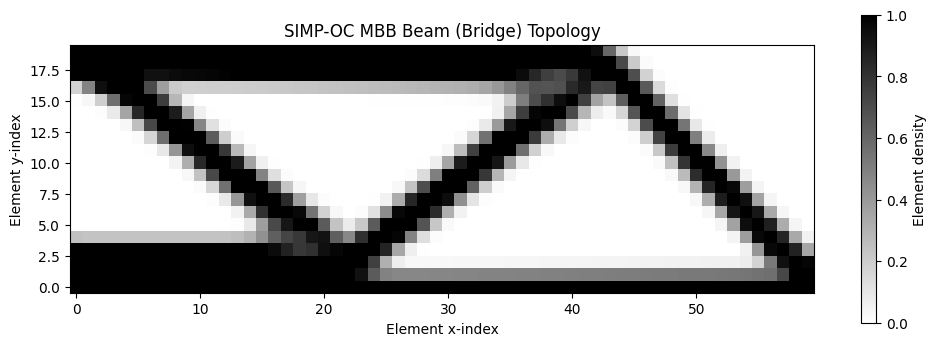

In [ ]:
def run_simp_oc_mbb(
    nelx=60,
    nely=20,
    volfrac=0.30,
    penal=3.0,
    rmin=1.5,
    max_iter=100,
    tol=0.01,
    move=0.20
):
    """SIMP-OC configured for an MBB Half-Beam (Bridge Setup)"""
    E0 = 1.0
    Emin = 1e-9
    nu = 0.3

    KE = element_stiffness(nu)
    edof = build_edof(nelx, nely)
    iK = np.repeat(edof, 8, axis=1).flatten()
    jK = np.tile(edof, (1, 8)).flatten()
    ndof = 2*(nelx+1)*(nely+1)

    F = np.zeros(ndof)

    # ---- 1. NEW LOAD: Downward unit force at top-left corner ----
    top_left_node = 0 * (nely + 1) + nely
    F[2 * top_left_node + 1] = -1.0

    # ---- 2. NEW SUPPORTS: Roller symmetry left, Roller support bottom-right ----
    # Horizontal fixed on the left edge
    left_nodes = np.array([iy for iy in range(nely + 1)])
    fixed_left_x = 2 * left_nodes

    # Vertical fixed at bottom-right
    bottom_right_node = nelx * (nely + 1) + 0
    fixed_bottom_right_y = np.array([2 * bottom_right_node + 1])

    fixed = np.unique(np.concatenate((fixed_left_x, fixed_bottom_right_y)))
    free = np.setdiff1d(np.arange(ndof), fixed)

    H = build_sensitivity_filter(nelx, nely, rmin)
    rho = np.full((nely, nelx), volfrac, dtype=float)
    history = []

    for iteration in range(1, max_iter+1):
        rho_flat = rho.T.flatten()
        E_e = Emin + rho_flat**penal*(E0-Emin)
        sK = (E_e[:, None] * KE.flatten()[None, :]).flatten()

        K = coo_matrix((sK, (iK, jK)), shape=(ndof, ndof)).tocsr()
        K = (K + K.T)*0.5

        U = np.zeros(ndof)
        U[free] = spsolve(K[free, :][:, free], F[free])

        Ue = U[edof]
        ce = np.einsum("ei,ij,ej->e", Ue, KE, Ue)
        compliance = float(np.sum(E_e*ce))

        dc_flat = -penal*(E0-Emin)*rho_flat**(penal-1)*ce
        dc = dc_flat.reshape(nelx, nely).T
        dc_filtered = filter_sensitivity(H, rho, dc, nelx, nely)

        dv = np.ones_like(rho)
        l1, l2 = 0.0, 1e9
        rho_new = rho.copy()

        for _ in range(100):
            lmid = 0.5*(l1+l2)
            ratio = np.maximum(0.0, -dc_filtered/(dv*lmid + 1e-30))
            candidate = rho*np.sqrt(ratio)
            rho_new = np.maximum(0.001, np.maximum(rho-move, np.minimum(1.0, np.minimum(rho+move, candidate))))

            if rho_new.mean() > volfrac:
                l1 = lmid
            else:
                l2 = lmid
            if (l2-l1)/(l2+l1+1e-30) < 1e-4:
                break

        change = float(np.max(np.abs(rho_new-rho)))
        rho = rho_new
        history.append({"iteration": iteration, "compliance": compliance, "volume_fraction": float(rho.mean()), "change": change})

        if iteration == 1 or iteration % 10 == 0 or change < tol:
            print(f"Iter {iteration:3d} | C = {compliance:.6e} | V = {rho.mean():.6f} | change = {change:.5f}")
        if change < tol:
            break

    return rho, history

# Run MBB Beam simulation
rho_mbb, history_mbb = run_simp_oc_mbb(nelx=60, nely=20, volfrac=0.40, rmin=1.5)

# Plot the resulting Bridge structure
plt.figure(figsize=(12, 4))
plt.imshow(rho_mbb, origin="lower", cmap="gray_r", vmin=0.0, vmax=1.0, interpolation="nearest")
plt.colorbar(label="Element density")
plt.title("SIMP-OC MBB Beam (Bridge) Topology")
plt.xlabel("Element x-index")
plt.ylabel("Element y-index")
plt.show()

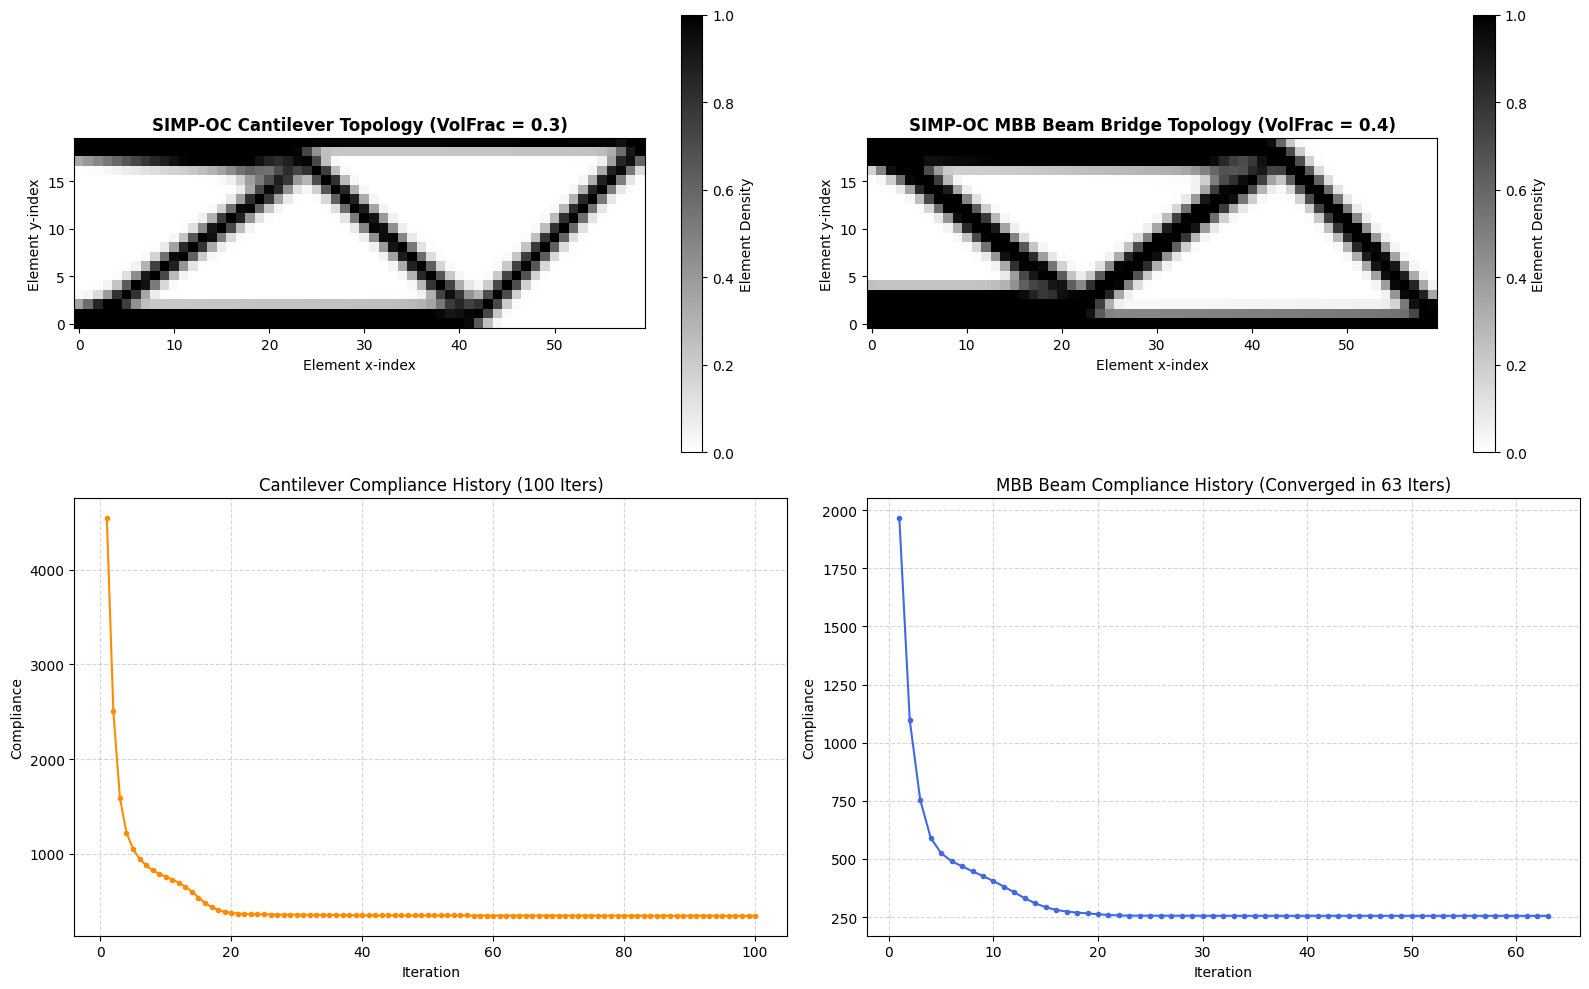

In [ ]:
import matplotlib.pyplot as plt

# Create a multi-plot comparison figure
fig, axs = plt.subplots(2, 2, figsize=(16, 10))

# 1. Cantilever Beam Topology Plot
im1 = axs[0, 0].imshow(rho_final, origin="lower", cmap="gray_r", vmin=0.0, vmax=1.0, interpolation="nearest")
fig.colorbar(im1, ax=axs[0, 0], label="Element Density")
axs[0, 0].set_title("SIMP-OC Cantilever Topology (VolFrac = 0.3)", fontsize=12, fontweight='bold')
axs[0, 0].set_xlabel("Element x-index")
axs[0, 0].set_ylabel("Element y-index")

# 2. MBB Beam (Bridge) Topology Plot
im2 = axs[0, 1].imshow(rho_mbb, origin="lower", cmap="gray_r", vmin=0.0, vmax=1.0, interpolation="nearest")
fig.colorbar(im2, ax=axs[0, 1], label="Element Density")
axs[0, 1].set_title("SIMP-OC MBB Beam Bridge Topology (VolFrac = 0.4)", fontsize=12, fontweight='bold')
axs[0, 1].set_xlabel("Element x-index")
axs[0, 1].set_ylabel("Element y-index")

# 3. Cantilever Compliance History Plot
cant_iters = [item["iteration"] for item in history]
cant_compl = [item["compliance"] for item in history]
axs[1, 0].plot(cant_iters, cant_compl, color='darkorange', marker='.', linewidth=1.5)
axs[1, 0].set_title("Cantilever Compliance History (100 Iters)", fontsize=12)
axs[1, 0].set_xlabel("Iteration")
axs[1, 0].set_ylabel("Compliance")
axs[1, 0].grid(True, linestyle='--', alpha=0.5)

# 4. MBB Beam Compliance History Plot
mbb_iters = [item["iteration"] for item in history_mbb]
mbb_compl = [item["compliance"] for item in history_mbb]
axs[1, 1].plot(mbb_iters, mbb_compl, color='royalblue', marker='.', linewidth=1.5)
axs[1, 1].set_title("MBB Beam Compliance History (Converged in 63 Iters)", fontsize=12)
axs[1, 1].set_xlabel("Iteration")
axs[1, 1].set_ylabel("Compliance")
axs[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Run MBB Beam simulation at the same volume fraction (0.30)
rho_mbb_30, history_mbb_30 = run_simp_oc_mbb(nelx=60, nely=20, volfrac=0.30, rmin=1.5)

# Calculate structural efficiency under identical volume constraints
cantilever_final_compliance = history[-1]['compliance']
mbb_final_compliance = history_mbb_30[-1]['compliance']

print("\n--- Comparison at Volume Fraction = 0.30 ---")
print(f"Cantilever Beam Final Compliance: {cantilever_final_compliance:.4f}")
print(f"MBB Bridge Beam Final Compliance: {mbb_final_compliance:.4f}")
print(f"Stiffness Ratio (MBB / Cantilever): {cantilever_final_compliance / mbb_final_compliance:.2f}x stiffer")

Iter   1 | C = 4.662139e+03 | V = 0.299990 | change = 0.20000
Iter  10 | C = 7.321006e+02 | V = 0.299994 | change = 0.20000
Iter  20 | C = 3.619280e+02 | V = 0.299986 | change = 0.10897
Iter  30 | C = 3.546737e+02 | V = 0.299994 | change = 0.07009
Iter  40 | C = 3.530246e+02 | V = 0.300008 | change = 0.06519
Iter  50 | C = 3.518658e+02 | V = 0.299999 | change = 0.05798
Iter  60 | C = 3.508651e+02 | V = 0.299988 | change = 0.05050
Iter  70 | C = 3.497335e+02 | V = 0.299995 | change = 0.04367
Iter  80 | C = 3.487618e+02 | V = 0.300007 | change = 0.03808
Iter  90 | C = 3.478864e+02 | V = 0.300010 | change = 0.03319
Iter 100 | C = 3.465834e+02 | V = 0.300014 | change = 0.02763

--- Comparison at Volume Fraction = 0.30 ---
Cantilever Beam Final Compliance: 342.5534
MBB Bridge Beam Final Compliance: 346.5834
Stiffness Ratio (MBB / Cantilever): 0.99x stiffer


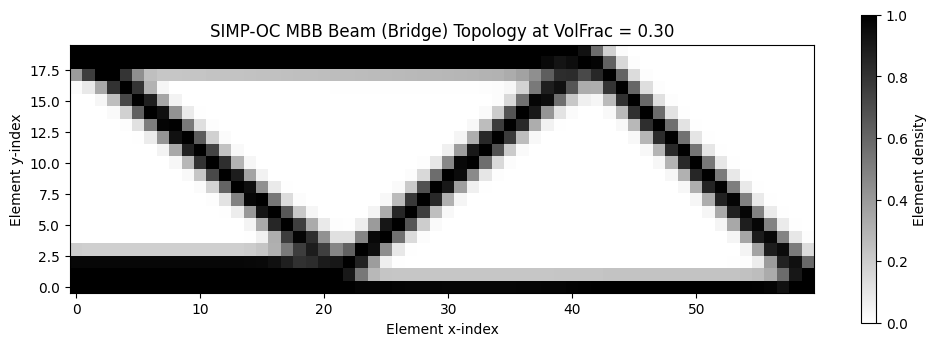

In [ ]:
# Plot the resulting Bridge structure at 0.30 volume fraction
plt.figure(figsize=(12, 4))
plt.imshow(rho_mbb_30, origin="lower", cmap="gray_r", vmin=0.0, vmax=1.0, interpolation="nearest")
plt.colorbar(label="Element density")
plt.title("SIMP-OC MBB Beam (Bridge) Topology at VolFrac = 0.30")
plt.xlabel("Element x-index")
plt.ylabel("Element y-index")
plt.show()

In [ ]:
# Run MBB Beam simulation at a higher volume fraction (0.50)
rho_mbb_50, history_mbb_50 = run_simp_oc_mbb(nelx=60, nely=20, volfrac=0.50, rmin=1.5)

# Compare compliance values
print(f"\n--- Compliance Comparison for MBB Bridge ---")
print(f"Compliance at Vf = 0.30: {history_mbb_30[-1]['compliance']:.4f}")
print(f"Compliance at Vf = 0.40: {history_mbb[-1]['compliance']:.4f}")
print(f"Compliance at Vf = 0.50: {history_mbb_50[-1]['compliance']:.4f}")

Iter   1 | C = 1.007022e+03 | V = 0.500000 | change = 0.20000
Iter  10 | C = 2.726474e+02 | V = 0.500006 | change = 0.13075
Iter  20 | C = 2.124892e+02 | V = 0.500000 | change = 0.11855
Iter  30 | C = 2.051361e+02 | V = 0.500012 | change = 0.03824
Iter  40 | C = 2.044112e+02 | V = 0.499997 | change = 0.03281
Iter  50 | C = 2.040812e+02 | V = 0.499999 | change = 0.02139
Iter  60 | C = 2.037291e+02 | V = 0.500000 | change = 0.01217
Iter  70 | C = 2.035448e+02 | V = 0.499993 | change = 0.02094
Iter  80 | C = 2.034500e+02 | V = 0.500012 | change = 0.01708
Iter  90 | C = 2.033635e+02 | V = 0.500001 | change = 0.01190
Iter  94 | C = 2.033088e+02 | V = 0.499994 | change = 0.00993

--- Compliance Comparison for MBB Bridge ---
Compliance at Vf = 0.30: 346.5834
Compliance at Vf = 0.40: 255.3541
Compliance at Vf = 0.50: 203.3088


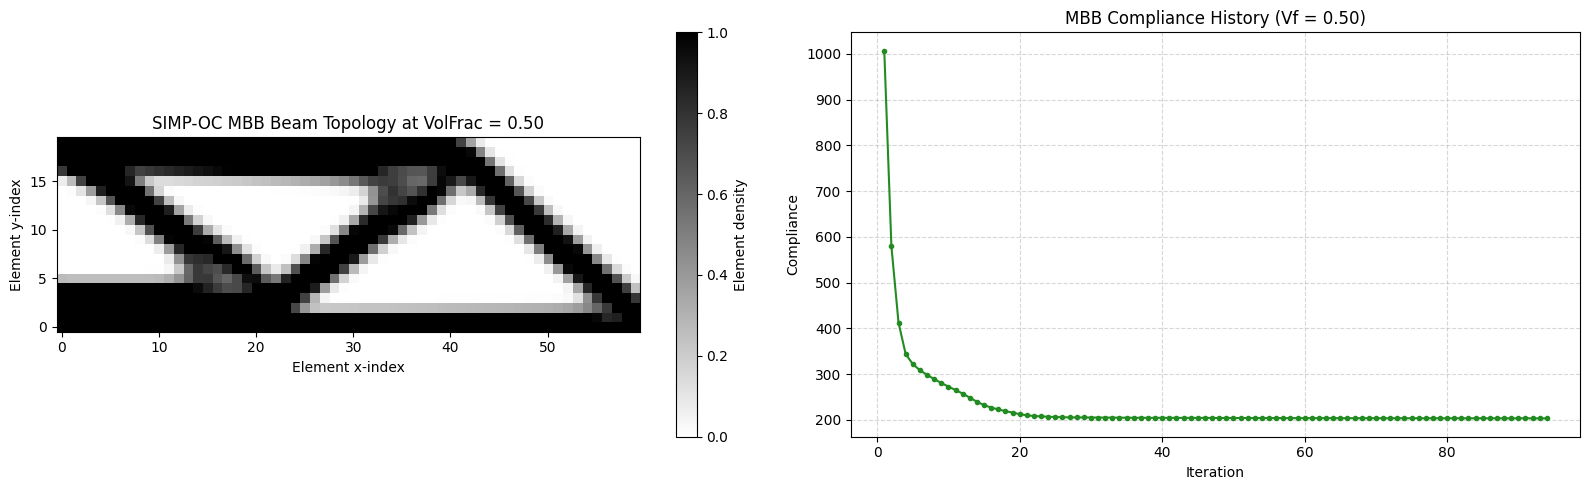

In [ ]:
# Plot the resulting Bridge structure and compliance history at 0.50 volume fraction
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

# 1. Topology
im = axs[0].imshow(rho_mbb_50, origin="lower", cmap="gray_r", vmin=0.0, vmax=1.0, interpolation="nearest")
fig.colorbar(im, ax=axs[0], label="Element density")
axs[0].set_title("SIMP-OC MBB Beam Topology at VolFrac = 0.50")
axs[0].set_xlabel("Element x-index")
axs[0].set_ylabel("Element y-index")

# 2. Compliance Curve
iters = [item["iteration"] for item in history_mbb_50]
compl = [item["compliance"] for item in history_mbb_50]
axs[1].plot(iters, compl, color='forestgreen', marker='.', linewidth=1.5)
axs[1].set_title("MBB Compliance History (Vf = 0.50)")
axs[1].set_xlabel("Iteration")
axs[1].set_ylabel("Compliance")
axs[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()